# 🔍 Vehicle Dataset Verification
Notebook này giúp:
- Kiểm tra số lượng ảnh/label mỗi split
- Trực quan hóa ảnh + BBox để kiểm tra dữ liệu

In [1]:
import os
import numpy as np
from PIL import Image
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.patches as patches
%matplotlib inline

DATASET_DIR = "VEHICLE_DATASET_YOLO"  # output of 01_data_pipeline.ipynb
CLASS_NAMES = ["Bus", "Motorcycle", "Car", "Truck"]
COLORS = ['#FF4444', '#44FF44', '#4488FF', '#FFAA00']

print('[OK] Config loaded')

[OK] Config loaded


In [2]:
print('=' * 60)
print(f'{"Split":<8} {"Images":<10} {"Labels":<10} {"Missing":<10} {"Objects":<10}')
print('-' * 60)

total_imgs = 0
total_objs = 0
all_class_dist = defaultdict(int)

for split in ['train', 'val', 'test']:
    s_img = os.path.join(DATASET_DIR, split, 'images')
    s_lbl = os.path.join(DATASET_DIR, split, 'labels')
    
    if not os.path.exists(s_img): continue
    
    imgs = [f for f in os.listdir(s_img) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    lbls = set(os.path.splitext(f)[0] for f in os.listdir(s_lbl) if f.endswith('.txt'))
    
    missing = 0
    obj_count = 0
    for img_f in imgs:
        base = os.path.splitext(img_f)[0]
        if base not in lbls:
            missing += 1
        else:
            with open(os.path.join(s_lbl, base + '.txt')) as f:
                for line in f:
                    if not line.strip(): continue
                    cls_id = int(line.split()[0])
                    all_class_dist[CLASS_NAMES[cls_id]] += 1
                    obj_count += 1
                    
    total_imgs += len(imgs)
    total_objs += obj_count
    status = 'OK' if missing == 0 else 'WARN'
    print(f'{split:<8} {len(imgs):<10} {len(lbls):<10} {missing:<10} {obj_count:<10} [{status}]')

# --- Phan bo lop tren toan bo dataset ---
print('\n' + '=' * 60)
print('PHAN BO LOP (so bounding box - toan bo dataset):')
print('-' * 60)
for cls in CLASS_NAMES:
    print(f'  {cls:<12}: {all_class_dist.get(cls, 0)}')
print('-' * 60)
if all_class_dist:
    mx, mn = max(all_class_dist.values()), min(all_class_dist.values())
    print(f'  Ti le cao/thap: {mx/mn:.2f}:1')
print(f'  TONG object   : {sum(all_class_dist.values())}')
print('=' * 60)

Split    Images     Labels     Missing    Objects   
------------------------------------------------------------
train    3357       3357       0          4869       [OK]
val      324        324        0          466        [OK]
test     167        167        0          277        [OK]

PHAN BO LOP (so bounding box - toan bo dataset):
------------------------------------------------------------
  Bus         : 1252
  Motorcycle  : 1289
  Car         : 2024
  Truck       : 1047
------------------------------------------------------------
  Ti le cao/thap: 1.93:1
  TONG object   : 5612


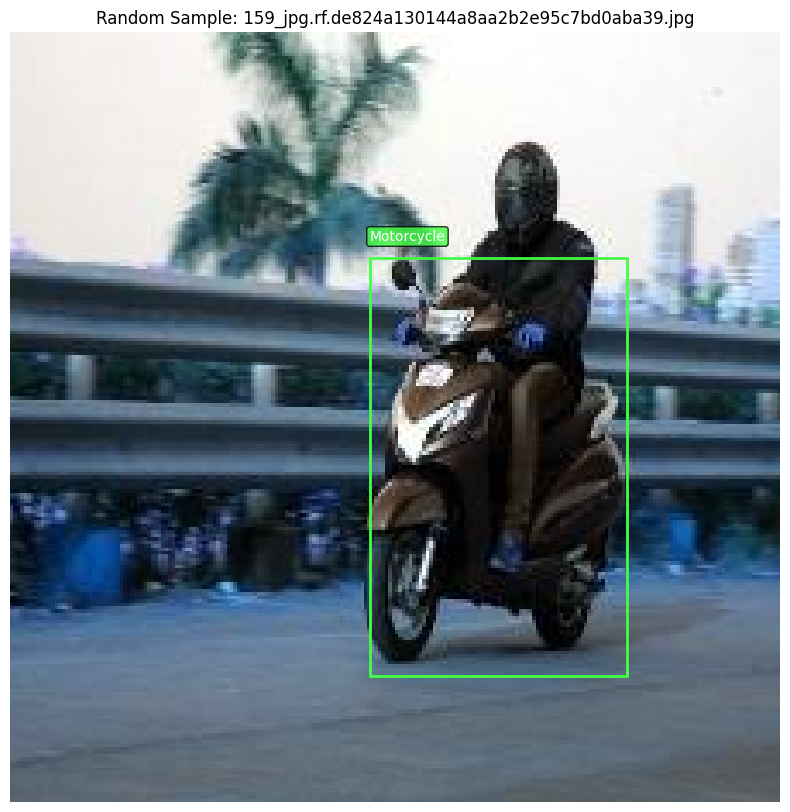

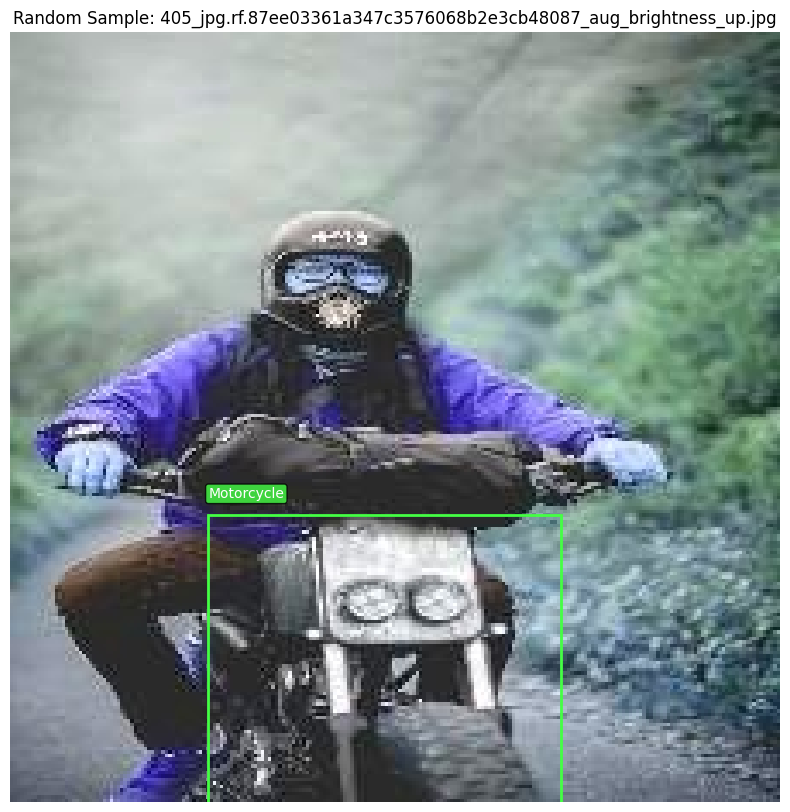

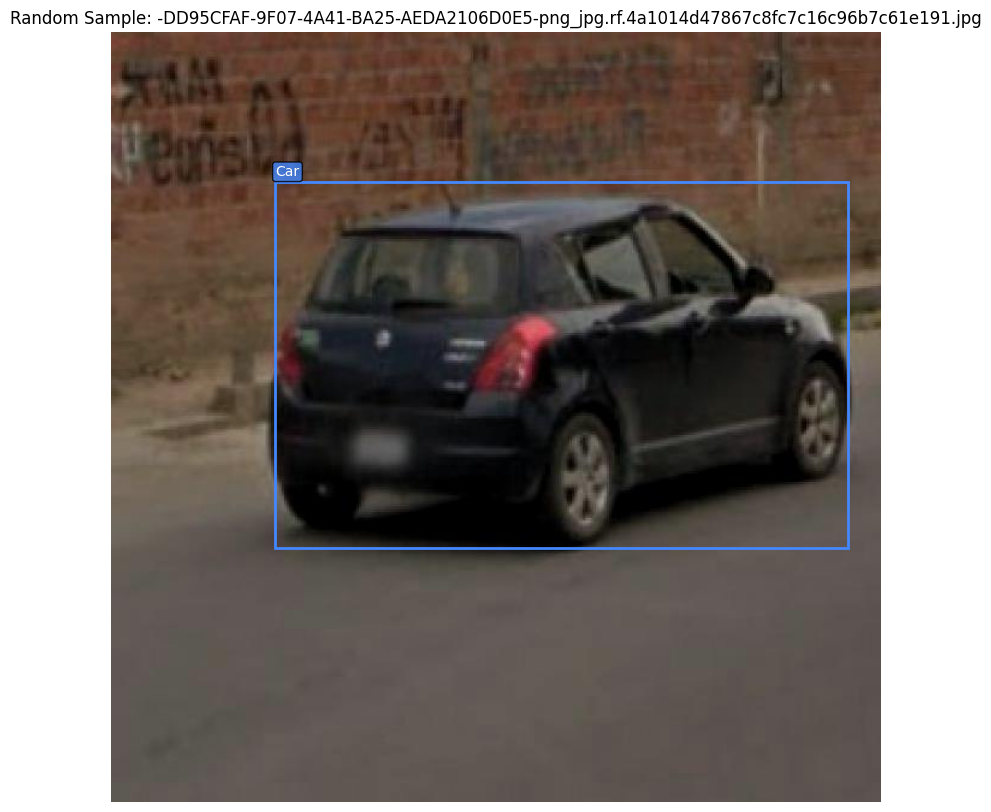

In [3]:
def draw_annotations(img_path, lbl_path, title=''):
    img = Image.open(img_path).convert('RGB')
    w, h = img.size
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    ax.imshow(img)
    
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if not parts: continue
                cls_id = int(parts[0])
                cx, cy, bw, bh = [float(x) for x in parts[1:5]]
                
                px = (cx - bw/2) * w
                py = (cy - bh/2) * h
                pw = bw * w
                ph = bh * h
                
                color = COLORS[cls_id % len(COLORS)]
                rect = patches.Rectangle((px, py), pw, ph, linewidth=2, edgecolor=color, facecolor='none')
                ax.add_patch(rect)
                ax.text(px, py-5, CLASS_NAMES[cls_id], color='white', fontsize=10,
                        bbox=dict(boxstyle='round,pad=0.2', facecolor=color, alpha=0.8))
                
    ax.set_title(title)
    ax.axis('off')
    plt.show()

# Show 3 random samples from train
import random
s_img = os.path.join(DATASET_DIR, 'train', 'images')
s_lbl = os.path.join(DATASET_DIR, 'train', 'labels')
if os.path.exists(s_img):
    all_samples = [f for f in os.listdir(s_img) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    random_samples = random.sample(all_samples, min(3, len(all_samples)))
    for sample in random_samples:
        lbl_name = os.path.splitext(sample)[0] + '.txt'
        draw_annotations(os.path.join(s_img, sample), os.path.join(s_lbl, lbl_name), f'Random Sample: {sample}')